# Multi-Dimensional Parameter Sweeps & Charge Dispersion

In previous tutorials, we explored 1D amplitude sweeps and 2D frequency–amplitude landscapes at fixed circuit parameters. This notebook introduces multi-dimensional parameter sweep (`circuit.sweep()`) to investigate how resonances depend on the offset charge $n_g$ of the transmon, reproducing the charge-averaged scar maps from **Dai et al. (Phys. Rev. X 16, 011011, 2026)**.


### The `circuit.sweep()` Engine
QBrAn provides a unified interface to sweep arbitrary circuit parameters simultaneously with drive parameters:
* **Targeting Parameters**: Uses a dot-notation dictionary, e.g. `{"tmon.ng": ngs}` or `{"buffer.E_osc": ...}`, or interaction couplings `{"g_tmon_res": ...}`.
* **Return Structure (`SweepResult`)**: Automatically packs results into multidimensional tensors of shape: $\text{shape} = (*\text{param\_dims}, *\text{drive\_dims}, n_{\text{tracked}})$

In [1]:
import qbran as br

import numpy as np
import matplotlib.pyplot as plt

# Circuit definition
# Parameter from Dai et al. Phys. Rev. X 16, 011011 (2026)
tmon = br.Transmon(EJ=16.2856, EC=0.17013, ng=0.0, truncated_dim=18, name="tmon")
circuit = br.HilbertSpace([tmon])

freq_drive = 8.2325
amp_drive  = np.linspace(0.0, 3.1, 200)

## 1. Charge Dispersion of Floquet Resonances

For a transmon in the $E_J / E_C \gg 1$ regime, low-lying states ($|0\rangle, |1\rangle$) exhibit exponentially suppressed charge dispersion. However, higher excited states approaching or exceeding the Josephson cosine barrier disperse significantly with offset charge $n_g$.

When a microwave drive tone excites a multi-photon transition connecting a low-lying state to a high-lying transmon level, the resonance condition shifts periodically as a function of $n_g$.

Below, we fix the drive frequency at $\omega_d / 2\pi = 8.2325\text{ GHz}$ and sweep the offset charge $n_g \in [-0.5, 0.5]$ while ramping the drive amplitude $\Omega_d$, tracking the transmon ground state $|0\rangle$.

In [2]:
ngs = np.linspace(-0.5, 0.5, 301)

tracking = [circuit.state_to_index(0)]
opt = br.Options(tracked_states=tracking)

sweep = circuit.sweep(
    parameters={
        "tmon.ng": ngs
    }, 
    drive_freq=freq_drive, 
    drive_amp=amp_drive, 
    kind="propagator", options=opt
)

Parameter Sweep: 100%|██████████| 301/301 [00:18<00:00, 16.68it/s]


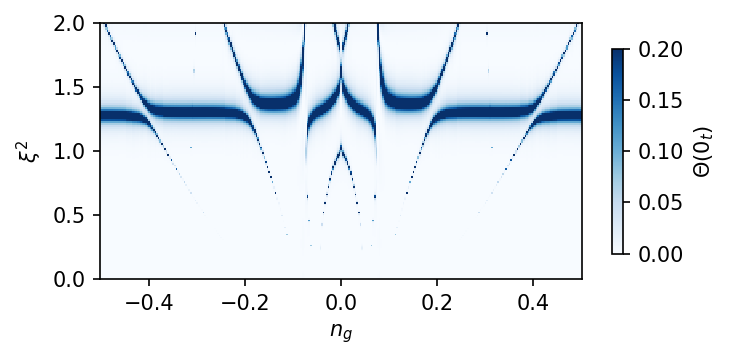

In [ ]:
def AmpToXi(amp, freq):
    """Dimensionless drive amplitude from Dai et al."""
    nzpf = (tmon.EJ/(32 * tmon.EC))**(1/4)
    return (2* nzpf * freq * amp) / (freq**2 - tmon.E01**2)
xi = AmpToXi(amp_drive[:, None], freq_drive)

hybr = sweep.hybridization[:, 0, :, 0].T

fig, ax = plt.subplots(figsize=(5, 2.5), dpi=150)
ax.pcolormesh(ngs, xi**2, hybr, norm='linear', cmap='Blues', vmin=0.0, vmax=0.2)
fig.colorbar(ax.collections[0], ax=ax, label=r"$\Theta(0_t)$", shrink=0.8)
ax.set_ylim(0.0, 2.0)
ax.set_xlabel(r"$n_g$")
ax.set_ylabel(r"$\xi^2$")
fig.tight_layout()
plt.show()

## 2. Charge-Averaged Scar Maps

In realistic superconducting processors, the offset charge $n_g$ is not static. Environmental effects cause $n_g$ to drift randomly over time. In the next cells we simulate the ensemble average over $n_g \in [-0.5, 0.5]$.

To simulate this experiment, we execute a **3D parameter sweep** over:
1. Offset charge: $n_g \in [-0.5, 0.5]$ (50 points),
2. Drive frequency: $\omega_d / 2\pi \in [10.0, 11.5]\text{ GHz}$ (200 points),
3. Drive amplitude: $\Omega_d \in [0.0, 5.3]$ (100 points),

tracking the transmon first excited state $|1\rangle$.

In [12]:
freq_drive_avg = np.linspace(10.0, 11.5, 200)
amp_drive_avg  = np.linspace(0.0, 5.3, 100)
xi_avg = AmpToXi(amp_drive_avg[:, None], freq_drive_avg[None, :])

ngs_avg = np.linspace(-0.5, 0.5, 50)

tracking_avg = [circuit.state_to_index(1)]
opt_avg = br.Options(tracked_states=tracking_avg)

sweep_avg = circuit.sweep(
    parameters={
        "tmon.ng": ngs_avg
    }, 
    drive_freq=freq_drive_avg, 
    drive_amp=amp_drive_avg, 
    kind="propagator", options=opt_avg
)

Parameter Sweep: 100%|██████████| 50/50 [04:54<00:00,  5.89s/it]


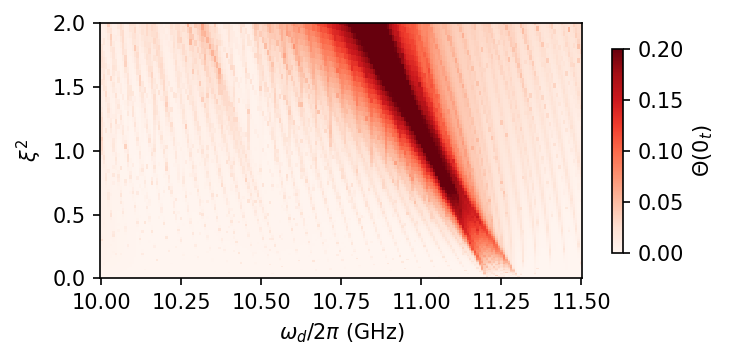

In [17]:
# Average over the charge offset
hybr_avg = np.mean(sweep_avg.hybridization, axis=0)
hybr_avg = hybr_avg[:, :, 0].T

fig, ax = plt.subplots(figsize=(5, 2.5), dpi=150)
ax.pcolormesh(freq_drive_avg, xi_avg**2, hybr_avg, norm='linear', cmap='Reds', vmin=0.0, vmax=0.2)
fig.colorbar(ax.collections[0], ax=ax, label=r"$\Theta(0_t)$", shrink=0.8)
ax.set_ylim(0.0, 2.0)
ax.set_ylabel(r"$\xi^2$")
ax.set_xlabel(r"$\omega_d/2\pi$ (GHz)")
fig.tight_layout()
plt.show()

## 3. References
* W. Dai, S. Hazra, D. K. Weiss, et al., *"Characterization of Drive-Induced Unwanted State Transitions in Superconducting Circuits"*, [Phys. Rev. X **16**, 011011 (2026)](https://doi.org/10.1103/PhysRevX.16.011011) (arXiv:2506.24070).